# Measured against modelled on the ten surveys: the expectation gate, the throughput residuals and the power that does not follow

**Question:** Which of the quantities the engine reports for the HP500 surveys does it reproduce, which does it not, and does the live engine still give the committed backbone document?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- apply the expectation gate of the real cases, whose ranges come from the measurement and from crushing relations and not from the engine;
- read the throughput residuals against the setting and against the feed f80, and say which one the model captures;
- compare the modelled power, in its two forms, with the measured power, and read the negative result;
- confirm that the engine's live results are the committed backbone document.

## Setup

Numpy and matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports add the expectation gate and the real-case definitions, the engine's two power forms and the backbone builder, to those of notebook 01.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone
from pipeline.model.crusher import evaluate, operating_from_survey
from pipeline.model.crusher.capacity import bond_power, calibrated_power
from pipeline.model.crusher.hp500 import HP500_BLEND_WI_KWH_T
from pipeline.cases import hp500_cases
from pipeline.oracles import bond_energy_kwh_t
from pipeline.core.expect import check, ExpectationError
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The ten HP500 surveys again, and the committed backbone document that the pipeline wrote from them. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the ten survey rows are transcribed from Table A1 of the paper. Files read: `data/examples/hp500-surveys.csv` and `data/derived/hp500/backbone.json`, the latter holding for each survey the measured values and the engine's results (contract `hp500-backbone`).

The cell reads both and runs the calibrated engine at the ten surveys.

In [2]:
# Read the surveys and the committed backbone, and run the calibrated engine on each survey
surveys = read_surveys().accepted
committed = json.loads((ROOT / "data" / "derived" / "hp500" / "backbone.json").read_text(encoding="utf-8"))
runs = [evaluate(operating_from_survey(s.css_mm, s.f80_mm)) for s in surveys]
css = np.array([s.css_mm for s in surveys])
f80 = np.array([s.f80_mm for s in surveys])
measured_q = np.array([s.feed_tph for s in surveys])
measured_kw = np.array([s.power_kw for s in surveys])
print("surveys:", len(surveys), "| committed engine version:", committed["engine_version"])

surveys: 10 | committed engine version: 0.09.003


## Method

**Step 1, the expectation gate.** Each real case carries a range for three results, written from the measurement and from crushing relations, never from the engine's value (`cases/hp500_cases.py`): the throughput within 29 percent of the measured feed rate, the P80 between 0.35 and 1.1 times the setting (the choke-fed crusher relation of Napier-Munn et al., 1996; https://search.worldcat.org/title/37081193), and a reduction ratio between 1.8 and 4. The cell builds the ten cases, applies `check` to the live results and lists the verdict for each.

In [3]:
# Apply the expectation gate of each real case to the live engine result
verdicts = {}
for case, r in zip(hp500_cases.build(surveys), runs):
    live = {"throughput_tph": r.throughput_tph, "p80_mm": r.p80, "reduction_ratio": r.reduction_ratio}
    try:
        check(case.id, case.expect, live)
        verdicts[case.id] = "inside"
    except ExpectationError as exc:
        verdicts[case.id] = str(exc)
print("inside every range:", sum(v == "inside" for v in verdicts.values()), "of", len(verdicts))
print({k: v for k, v in verdicts.items() if v != "inside"})

inside every range: 10 of 10
{}


**Step 2, the throughput residuals.** The residual of survey $i$ is the modelled minus the measured throughput, in percent of the measured. The question is which variable explains it. The cell computes the residuals and the correlation of the measured throughput with the setting and with the feed f80, and the same for the model, which depends on the setting only.

In [4]:
# Throughput residuals and the correlations of measured and modelled throughput with the setting and the f80
modelled_q = np.array([r.throughput_tph for r in runs])
residual = (modelled_q - measured_q) / measured_q * 100


def corr(a, b):
    return round(float(np.corrcoef(a, b)[0, 1]), 3)


print("mean error:", round(float(residual.mean()), 2), "% | mean absolute error:", round(float(np.abs(residual).mean()), 2), "%")
print("measured vs setting:", corr(measured_q, css), "| measured vs f80:", corr(measured_q, f80), "| modelled vs measured:", corr(modelled_q, measured_q))

mean error: -2.6 % | mean absolute error: 11.55 %
measured vs setting: 0.815 | measured vs f80: -0.086 | modelled vs measured: 0.815


The figure draws the residuals against the setting on the left and against the f80 on the right, with the 29 percent band of the expectation gate.

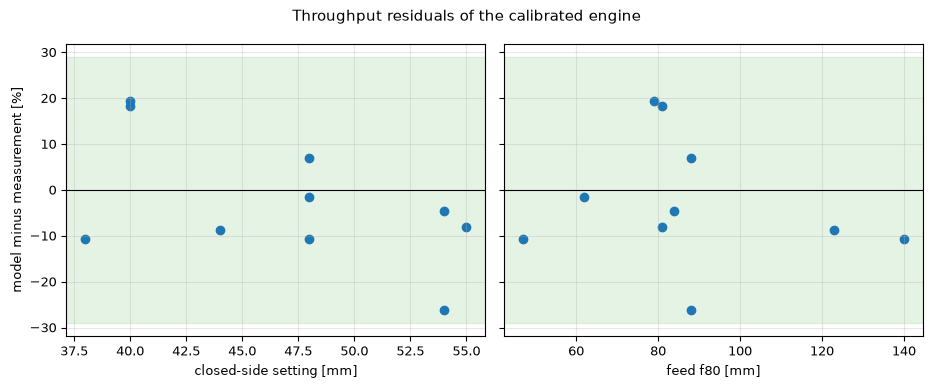

In [5]:
# Plot the throughput residuals against the setting and against the feed f80, with the 29 % band
fig, (left, right) = plt.subplots(1, 2, figsize=(9.4, 3.9), sharey=True)
for ax, x, name in ((left, css, "closed-side setting [mm]"), (right, f80, "feed f80 [mm]")):
    ax.axhspan(-29, 29, color="tab:green", alpha=0.12)
    ax.axhline(0, color="k", lw=0.8)
    ax.scatter(x, residual)
    ax.set_xlabel(name)
left.set_ylabel("model minus measurement [%]")
fig.suptitle("Throughput residuals of the calibrated engine")
fig.tight_layout()
plt.show()

Both panels sit inside the green band, so the engine passes the expectation gate on throughput for every survey. Neither panel shows a clean trend: the residuals do not grow with the setting, and against the f80 they do not organise either, the correlation of the measured throughput with the f80 being near zero. What is left over is scatter that neither variable explains. The two panels together say that the model captures what the setting contributes and that the rest of the plant's variation is outside the model's inputs.

**Step 3, the power.** The measured power is the plant's own kW reading. The engine reports it in two forms: the Bond draw of notebook 02 of topic 04, with the blend work index of 9 kWh/t, and the calibrated form of the paper, $P_c = 1.30\,P_d + 110$ kW, with the engine's Bond draw in place of the paper's size-specific $P_d$ (Rocha et al., 2024; Bond, 1952; https://onemine.org/documents/the-third-theory-of-comminution). The cell computes both for the ten surveys and prints their errors and their correlation with the measured power.

In [6]:
# Bare Bond power and the calibrated form for the ten surveys, against the measured power
bare = np.array([bond_power(r.throughput_tph, r.f80, r.p80, HP500_BLEND_WI_KWH_T) for r in runs])
calibrated = np.array([calibrated_power(v) for v in bare])


def mape(estimate):
    return round(float(np.mean(np.abs((estimate - measured_kw) / measured_kw)) * 100), 2)


print("measured range [kW]:", measured_kw.min(), measured_kw.max(), "| Bond draw range:", bare.min().round(1), bare.max().round(1))
print("mean absolute error, bare Bond:", mape(bare), "% | calibrated form:", mape(calibrated), "%")
print("correlation with the measured power, bare Bond:", corr(bare, measured_kw), "| measured vs setting:", corr(measured_kw, css))

measured range [kW]: 187.0 355.0 | Bond draw range: 196.1 237.5
mean absolute error, bare Bond: 26.88 % | calibrated form: 47.58 %
correlation with the measured power, bare Bond: -0.453 | measured vs setting: -0.818


The figure plots the measured power and the two modelled ones against the setting.

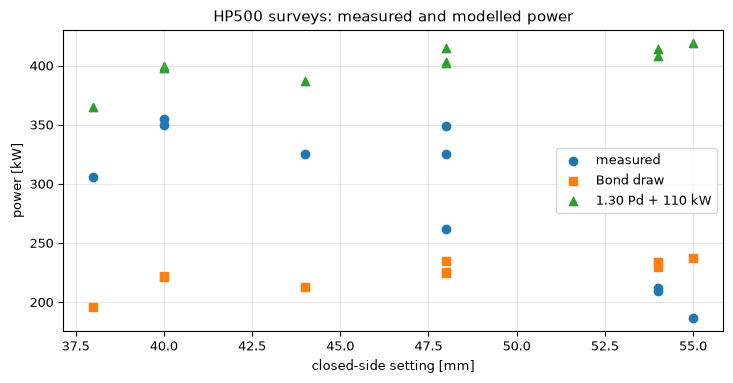

In [7]:
# Plot the measured and the two modelled powers against the setting
fig, ax = plt.subplots()
ax.scatter(css, measured_kw, label="measured", zorder=3)
ax.scatter(css, bare, marker="s", label="Bond draw")
ax.scatter(css, calibrated, marker="^", label="1.30 Pd + 110 kW")
ax.set_xlabel("closed-side setting [mm]")
ax.set_ylabel("power [kW]")
ax.set_title("HP500 surveys: measured and modelled power")
ax.legend()
fig.tight_layout()
plt.show()

The figure shows the negative result directly. The measured power falls as the setting opens, from 355 kW at 40 mm to 187 kW at 55 mm; the two modelled powers stay flat in a narrow band, near 200 to 240 kW for the Bond draw and 360 to 420 kW for the calibrated form, and the calibrated form sits far above every measured point. A flat Bond draw cannot follow a quantity that moves with the setting by a factor of two: closing the setting makes a finer product and raises the kWh per tonne, while the lower throughput in tonnes cancels it in the Bond draw, a cancellation that the plant's power does not show. The result is not hidden: the constants of the paper's form belong to the paper's own size-specific power, not to the classical Bond draw used here.

**Step 4, the one reproduction check.** The pipeline writes the engine's results at the ten surveys into the backbone document, and a test holds the two equal. The cell rebuilds the document from the surveys with the pipeline's own builder and compares it with the committed file, whole.

In [8]:
# Rebuild the backbone document from the surveys and compare it with the committed one
rebuilt = backbone.build(surveys, committed["engine_version"])
print("the rebuilt document equals the committed one:", rebuilt == committed)
print("survey 1 in the document, modelled throughput [t/h]:", committed["surveys"][0]["backbone"]["throughput_tph"])

the rebuilt document equals the committed one: True
survey 1 in the document, modelled throughput [t/h]: 1208.87


**Step 5, what calibrating changes.** The calibrated lane replaces the synthetic classification, the breakage and the capacity base by the paper's fit. The cell runs each survey twice, with the calibrated lane and with the synthetic one at the same operating point, and prints the mean of the three results over the ten surveys for each.

In [9]:
# Run each survey on the calibrated and on the synthetic lane and compare the mean results
from dataclasses import replace

pairs = [(r, evaluate(replace(operating_from_survey(s.css_mm, s.f80_mm), calibrated=False))) for r, s in zip(runs, surveys)]
for name, field in (("P80 [mm]", "p80"), ("throughput [t/h]", "throughput_tph"), ("power [kW]", "power_kw")):
    print(f"{name:18s} calibrated {np.mean([getattr(a, field) for a, _ in pairs]):7.1f}   synthetic {np.mean([getattr(b, field) for _, b in pairs]):7.1f}")

P80 [mm]           calibrated    29.7   synthetic    36.0
throughput [t/h]   calibrated  1088.0   synthetic   874.4
power [kW]         calibrated   401.1   synthetic   133.7


The calibration moves the throughput by about a quarter, from a mean near 880 to a mean near 1090 t/h that matches the plant's, and the mean P80 by several millimetres. It moves the power by a factor of three, from a Bond draw near 140 kW to the 1.30 Pd + 110 form near 400 kW, and that is the move that takes the model away from the measured 187 to 355 kW: the offset of 110 kW is larger than the Bond draw of some surveys. The calibration was fitted to the size and the capacity, and the power form was transplanted from the paper's size-specific power to a classical Bond draw it was never fitted to.

**Step 6, the specific energy.** Dividing the power by the tonnes gives the energy per tonne, the quantity a plant optimises. The measured value is the power over the measured feed rate, and the model's is the Bond energy of the oracle for the engine's own F80 and P80. The figure plots both against the setting.

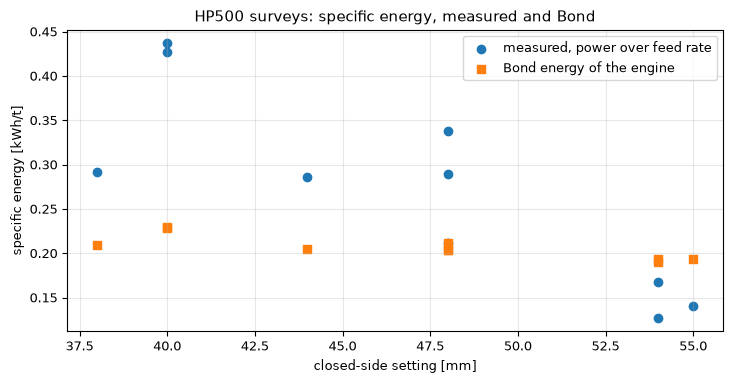

measured at 38 to 40 mm and at 54 to 55 mm [kWh/t]: [0.437 0.291 0.427] [0.128 0.167 0.14 ]
Bond energy range [kWh/t]: 0.19 0.229


In [10]:
# Measured specific energy against the oracle's Bond energy of the engine, per survey, against the setting
measured_kwh_t = measured_kw / measured_q
bond_kwh_t = np.array([bond_energy_kwh_t(r.f80, r.p80, HP500_BLEND_WI_KWH_T) for r in runs])
fig, ax = plt.subplots()
ax.scatter(css, measured_kwh_t, label="measured, power over feed rate")
ax.scatter(css, bond_kwh_t, marker="s", label="Bond energy of the engine")
ax.set_xlabel("closed-side setting [mm]")
ax.set_ylabel("specific energy [kWh/t]")
ax.set_title("HP500 surveys: specific energy, measured and Bond")
ax.legend()
fig.tight_layout()
plt.show()
print("measured at 38 to 40 mm and at 54 to 55 mm [kWh/t]:", measured_kwh_t[css <= 40].round(3), measured_kwh_t[css >= 54].round(3))
print("Bond energy range [kWh/t]:", bond_kwh_t.min().round(3), bond_kwh_t.max().round(3))

The measured energy per tonne triples as the setting closes from 55 to 40 mm, from about 0.13 to 0.14 kWh/t at 54 to 55 mm to 0.43 to 0.44 kWh/t at 40 mm (survey 7, at 38 mm, is the exception at 0.29), in the way that a finer product asks for more energy per tonne; the Bond energy of the engine moves only from 0.19 to 0.23 kWh/t. The plant's energy is much more sensitive to the setting than the model's, which is the same finding as in the power figure but in the units a plant uses. The Bond ratio between the sizes does not produce a threefold change from a 15 mm change of the setting, so the missing piece is in the energy law, not in the calibration of the sizes.

## Results

**Answer:** the engine reproduces the plant's throughput and does not reproduce its power. All ten surveys pass the expectation gate: throughput within 29 percent, P80 between 0.35 and 1.1 times the setting, reduction ratio between 1.8 and 4. The throughput residuals have a mean of -2.6 percent, no organised trend against the setting or against the f80, and a mean absolute error of 11.55 percent. The power does not: the measured kW falls from 355 to 187 as the setting opens, the Bond draw moves only between 196 and 237 kW and has a negative correlation with the measurement, and the calibrated form, at 47.58 percent mean absolute error, is the worse of the two forms the engine offers against a bare Bond draw at 26.88 percent. The rebuilt backbone document equals the committed one.

The first figure shows what the model leaves unexplained in the throughput, the second the power failing the plant. A validator would conclude that the throughput is a calibrated, partial success and the power an honest negative, which the product reports and does not hide, that the P80 can only be judged by the choke-fed relation since the paper gives no table of it, and that all these numbers are in sample, so none of them yet says how the engine behaves on a survey it was not fitted to.

## Summary

On real data the engine's throughput passes the gate and tracks the setting, its power does not track the plant and the product's own report says so, and every number of this notebook is in sample. The next notebook of this topic runs the state-of-the-art protocol of the source paper, the in-sample fit, and shows what that protocol can and cannot say; topic 06 then holds the surveys out.

## References

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Bond, F. C. (1952), The third theory of comminution, Transactions AIME 193, 484-494. https://onemine.org/documents/the-third-theory-of-comminution
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193